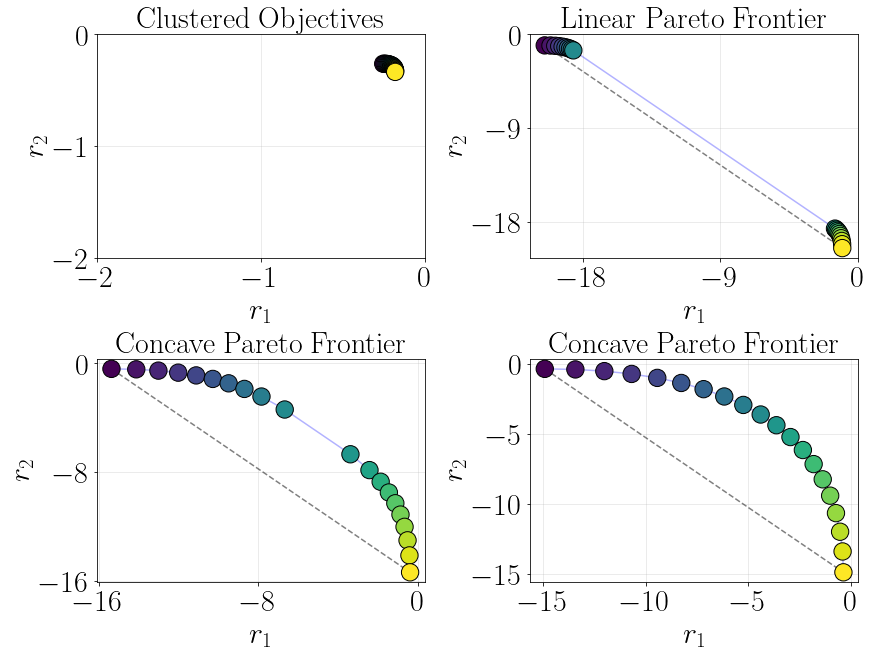

In [13]:
import json
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rc

rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
mpl.rcParams['savefig.dpi'] = 1200
mpl.rcParams['text.usetex'] = True  # not really needed

import matplotlib.ticker as mticker


# Input/output (no CLI args; edit here if needed)
JSON_FILE = "case_data.json"

data = json.loads(Path(JSON_FILE).read_text(encoding="utf-8"))
modes = data["modes"]
titles = [
      r"$\mathrm{Clustered~Objectives}$",
      r"$\mathrm{Linear~Pareto~Frontier}$",
      r"$\mathrm{Concave~Pareto~Frontier}$",
      r"$\mathrm{Concave~Pareto~Frontier}$"
    ]
w_values = np.array(data["w_values"], dtype=float)

grid_rows, grid_cols = 2, 2
max_axes = grid_rows * grid_cols
if len(modes) > max_axes:
    raise ValueError(f"Expected at most {max_axes} modes for a 2x2 grid, got {len(modes)}")

fig, axes = plt.subplots(grid_rows, grid_cols, figsize=(12, 9), constrained_layout=True)
axes = axes.ravel()

sc = None
fontsize = 30

for i, mode in enumerate(modes):
    case = data["cases"][mode]
    r1 = np.array(case["r1"], dtype=float)
    r2 = np.array(case["r2"], dtype=float)

    ax = axes[i]

    if mode != "aligned":
        ax.plot([r1[0], r1[-1]], [r2[0], r2[-1]], "k--", alpha=0.5, label=r"$\mathrm{Convex~Hull~(Mixing)}$")

    sc = ax.scatter(
        r1,
        r2,
        c=w_values,
        cmap="viridis",
        s=300,
        zorder=5,
        edgecolor="k",
    )
    ax.plot(r1, r2, "b-", alpha=0.3)

    ax.set_title(titles[i], fontsize=fontsize, fontweight="bold")
    if mode == 'aligned':
        ax.set_xticks([-2, -1, 0])
        ax.tick_params(labelsize=fontsize)
        ax.set_yticks([-2, -1, 0])
        ax.tick_params(labelsize=fontsize)
    elif mode == 'linear':
        ax.set_xticks([-18, -9, 0])
        ax.tick_params(labelsize=fontsize)
        ax.set_yticks([-18, -9, 0])
        ax.tick_params(labelsize=fontsize)
    elif mode == 'linear2':
        ax.set_xticks([-16, -8, 0])
        ax.tick_params(labelsize=fontsize)
        ax.set_yticks([-16, -8, 0])
        ax.tick_params(labelsize=fontsize)
    elif mode == 'concave':
        ax.set_xticks([-15, -10, -5, 0])
        ax.tick_params(labelsize=fontsize)
        ax.set_yticks([-15, -10, -5, 0])
        ax.tick_params(labelsize=fontsize)
    ax.set_xlabel(r"$r_1$", fontsize=fontsize)
    ax.set_ylabel(r"$r_2$", fontsize=fontsize)
    ax.grid(True, alpha=0.3)

for ax in axes[len(modes):]:
    ax.set_visible(False)


# cbar_ax = fig.add_axes([0.92, 0.15, 0.01, 0.7])
# fig.colorbar(sc, cax=cbar_ax, label="Preference Weight $w$ (0=Obj2, 1=Obj1)")
# cbar = fig.colorbar(
#     sc,
#     ax=axes[:len(modes)],
#     orientation="horizontal",
#     location="top",
#     pad=0.08,
#     fraction=0.05
# )
# cbar.ax.tick_params(labelsize=20)
# cbar.ax.xaxis.set_label_position("top")
# cbar.ax.xaxis.set_ticks_position("top")
# cbar.set_label(
#     r"$\mathrm{Preference~Weight}$",
#     fontsize=24
# )
fig.savefig('case.pdf', dpi=1200, bbox_inches="tight")

plt.show()

plt.close(fig)




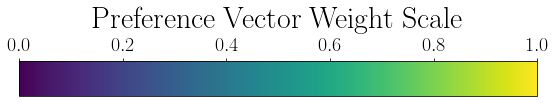

In [16]:
import json
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rc

rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
mpl.rcParams['savefig.dpi'] = 1200
mpl.rcParams['text.usetex'] = True  # not really needed

import matplotlib.ticker as mticker

# =========================
# Save colorbar as a separate figure
# =========================
fig_cb = plt.figure(figsize=(8, 1.2))  # 横向 colorbar
cax = fig_cb.add_axes([0.05, 0.4, 0.9, 0.4])  # [left, bottom, width, height]

cb = fig_cb.colorbar(
    sc,
    cax=cax,
    location="top",
    orientation="horizontal"
)

cb.ax.tick_params(labelsize=20)
cb.ax.xaxis.set_label_position("top")
cb.ax.xaxis.set_ticks_position("top")
cb.set_label(
    r"$\mathrm{Preference~Vector~Weight~Scale}$",
    fontsize=30,
    labelpad=8
)

fig_cb.savefig("case_colorbar.pdf", dpi=1200, bbox_inches="tight")
plt.show()
